# Mobile Game Player Spending Segmentation
## 03 — Exploratory Data Analysis and Feature Engineering

This notebook reads `mobile_game_players_cleaned.csv` from Stage 2 and explores player spending segments, purchase behavior, ad views, activity, genres, countries, devices, acquisition/payment channels, purchase timing, and date coverage. It creates activity-rate features for modelling and flags timing-related target leakage.



## 1. Read the cleaned dataset

This notebook uses the `mobile_game_players_cleaned.csv` file,

In [50]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from pathlib import Path

FILE_NAME = 'mobile_game_players_cleaned.csv'
if not Path(FILE_NAME).exists():
    raise FileNotFoundError(
        f'{FILE_NAME} was not found. Place the  cleaned CSV beside this notebook.'
    )

df = pd.read_csv(FILE_NAME)
segment_order = ['Minnow', 'Dolphin', 'Whale']
segment_colors = {'Minnow': '#6baed6', 'Dolphin': '#fd8d3c', 'Whale': '#756bb1'}
sns.set_theme(style='whitegrid')

print('File:', FILE_NAME)
print('Rows x columns:', df.shape)
print('Duplicate rows:', int(df.duplicated().sum()))
display(df.head())


File: mobile_game_players_cleaned.csv
Rows x columns: (247500, 25)
Duplicate rows: 0


,UserID,Age,Gender,Country,Device,GameGenre,SessionCount,AverageSessionLength,SpendingSegment,InAppPurchaseAmount,...,ActiveDays30d,PlayerLevel30d,AdsWatched30d,SocialActions30d,GuildMember,PushNotificationsOptIn,PurchaseCount30d,WinRate,InAppPurchaseAmountWasMissing,FirstPurchaseDaysAfterInstallWasMissing
0,PLAYER005364744676376,49.0,Male,Norway,Android,Battle Royale,9.0,12.83,Minnow,11.40,...,5.0,4.0,7.0,1.0,No,No,0.0,0.728,0,0
1,PLAYER447523025485744,15.0,Male,Switzerland,iOS,Action RPG,11.0,19.39,Minnow,6.37,...,3.0,4.0,6.0,3.0,No,Yes,0.0,0.183,0,0
2,PLAYER445146626174337,23.0,Male,China,Android,Fighting,9.0,8.87,Minnow,15.81,...,5.0,5.0,4.0,5.0,No,No,2.0,0.384,0,0
3,PLAYER673007615056419,31.0,Male,Mexico,Android,Racing,12.0,19.92,Minnow,13.49,...,8.0,8.0,8.0,1.0,Yes,No,0.0,0.265,0,0
4,PLAYER316428408427736,37.0,Female,India,Android,Battle Royale,10.0,15.23,Minnow,10.86,...,4.0,4.0,5.0,3.0,No,No,0.0,0.285,0,0


## 2. Analysis setup and data coverage

Convert only columns needed for calculations and plots; this is analysis preparation, Review if there is missing counts before interpreting date charts.

In [22]:
numeric_columns = [
    'Age', 'SessionCount', 'AverageSessionLength', 'InAppPurchaseAmount',
    'FirstPurchaseDaysAfterInstall', 'ActiveDays30d', 'PlayerLevel30d',
    'AdsWatched30d', 'SocialActions30d', 'PurchaseCount30d', 'WinRate'
]
for column in numeric_columns:
    if column in df.columns:
        text = df[column].astype('string').str.replace('$', '', regex=False).str.strip()
        df[column] = pd.to_numeric(text, errors='coerce')

def parse_date_column(series):
    text = series.astype('string').str.strip()
    result = pd.Series(pd.NaT, index=series.index, dtype='datetime64[ns]')
    formats = [('%Y-%m-%d', r'^\d{4}-\d{2}-\d{2}(?:[ T].*)?$'),
               ('%m/%d/%Y', r'^\d{1,2}/\d{1,2}/\d{4}$'),
               ('%d-%m-%Y', r'^\d{1,2}-\d{1,2}-\d{4}$')]
    for date_format, pattern in formats:
        mask = text.str.match(pattern, na=False)
        result.loc[mask] = pd.to_datetime(text.loc[mask], errors='coerce') if date_format == '%Y-%m-%d' else pd.to_datetime(text.loc[mask], format=date_format, errors='coerce')
    return result

for column in ['InstallDate', 'LastPurchaseDate']:
    if column in df.columns:
        df[column] = parse_date_column(df[column])

# Final canonical alias: one source row had the truncated device label 'Androi'.
if 'Device' in df.columns:
    df['Device'] = df['Device'].replace({'Androi': 'Android', 'androi': 'Android'})

print('Duplicate rows:', int(df.duplicated().sum()))
print('Missing value counts in key analysis columns:')
key_columns = [c for c in ['InstallDate','LastPurchaseDate','FirstPurchaseDaysAfterInstall','InAppPurchaseAmount','GameGenre','Country','Device'] if c in df.columns]
display(df[key_columns].isna().sum().to_frame('missing_rows'))


Duplicate rows: 0
Missing value counts in key analysis columns:


,missing_rows
InstallDate,0
LastPurchaseDate,0
FirstPurchaseDaysAfterInstall,0
InAppPurchaseAmount,0
GameGenre,0
Country,0
Device,0


## 3. Dataset size, date range, and distributions

In [23]:
print(f'Rows: {len(df):,}; columns: {df.shape[1]}')

Rows: 247,500; columns: 25


In [51]:
date_columns = ["InstallDate", "LastPurchaseDate"]

for column in date_columns:
    dates = pd.to_datetime(df[column], errors="coerce").dropna()

    if dates.empty:
        print(f"{column}: no valid dates")
    else:
        print(f"{column}: starts {dates.min().date()} and ends {dates.max().date()}")


InstallDate: starts 2022-07-16 and ends 2025-08-12
LastPurchaseDate: starts 2025-01-01 and ends 2025-08-13


### Age distribution
**What to look for:** the median and spread describe the player ages in this dataset. A histogram shows concentration and skew; it does not establish which age group is more valuable until compared with the target.


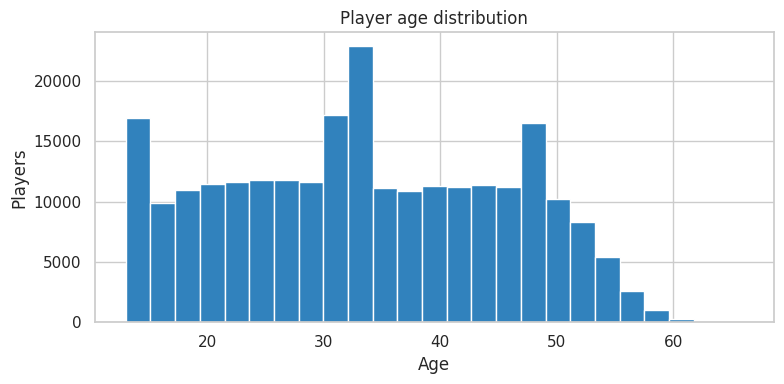

Age median: 33.0 | IQR: 19.0


In [24]:
plt.figure(figsize=(8,4))
plt.hist(df['Age'].dropna(), bins=25, color='#3182bd', edgecolor='white')
plt.title('Player age distribution')
plt.xlabel('Age'); plt.ylabel('Players')
plt.tight_layout(); plt.show()
print('Age median:', round(df['Age'].median(),1), '| IQR:', round(df['Age'].quantile(.75)-df['Age'].quantile(.25),1))


This chart shows which ages are common in the player base.

### Ad views in the first 30 days
**What it means:** This shows how many ads players watched in their first 30 days. It describes ad exposure, but does not tell us whether watching ads causes purchases; compare it with the purchase chart in Section 6.

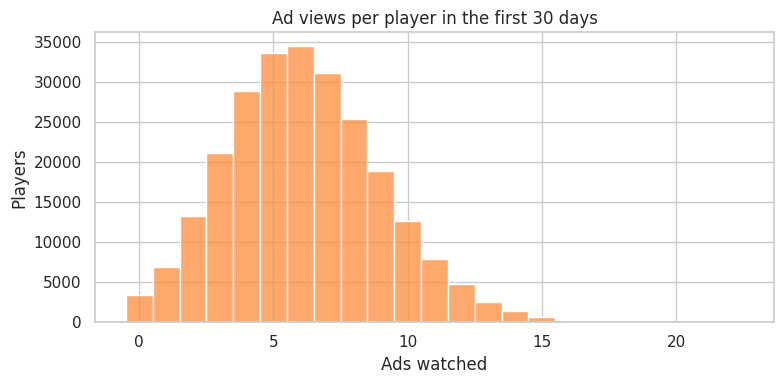

Median ad views: 6.0 | 90th percentile: 10.0


In [25]:
plt.figure(figsize=(8,4))
sns.histplot(df['AdsWatched30d'].dropna(), discrete=True, color='#fd8d3c')
plt.title('Ad views per player in the first 30 days')
plt.xlabel('Ads watched'); plt.ylabel('Players')
plt.tight_layout(); plt.show()
print('Median ad views:', df['AdsWatched30d'].median(), '| 90th percentile:', df['AdsWatched30d'].quantile(.90))


### Active days in the first 30 days
**What it means:** This shows how often players returned during the first 30 days. Players with more active days had more chances to see ads or make purchases, so compare behavior per active day when possible.


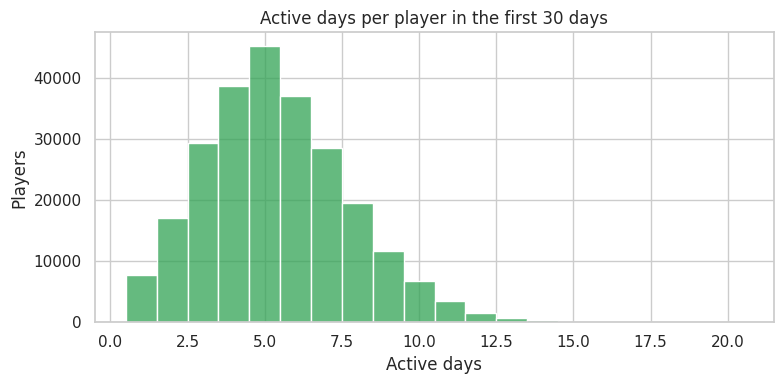

Median active days: 5.0 | 90th percentile: 8.0


In [26]:
plt.figure(figsize=(8,4))
sns.histplot(df['ActiveDays30d'].dropna(), discrete=True, color='#31a354')
plt.title('Active days per player in the first 30 days')
plt.xlabel('Active days'); plt.ylabel('Players')
plt.tight_layout(); plt.show()
print('Median active days:', df['ActiveDays30d'].median(), '| 90th percentile:', df['ActiveDays30d'].quantile(.90))


### Purchase count in the first 30 days
**What it means:** unlike positive IAP amount, `PurchaseCount30d > 0` is the more direct available indicator of at least one purchase in this dataset. Check its zero share and distribution before comparing segments.


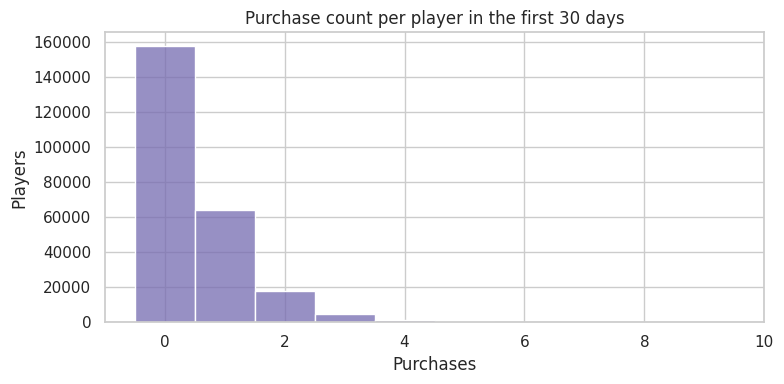

Players with zero recorded purchases: 63.8%
Median purchase count: 0.0


In [27]:
plt.figure(figsize=(8,4))
sns.histplot(df['PurchaseCount30d'].dropna(), discrete=True, color='#756bb1')
plt.title('Purchase count per player in the first 30 days')
plt.xlabel('Purchases'); plt.ylabel('Players')
plt.tight_layout(); plt.show()
print('Players with zero recorded purchases:', f"{(df['PurchaseCount30d'].fillna(0)==0).mean()*100:.1f}%")
print('Median purchase count:', df['PurchaseCount30d'].median())


**What it means:** This shows how many players made no purchases and how purchase counts are distributed. The zero-purchase group is important for deciding whom a campaign might try to convert.

## 4. What does the spending-segment mix look like?
**What it means:** The chart shows the size of each spending tier in the dataset.


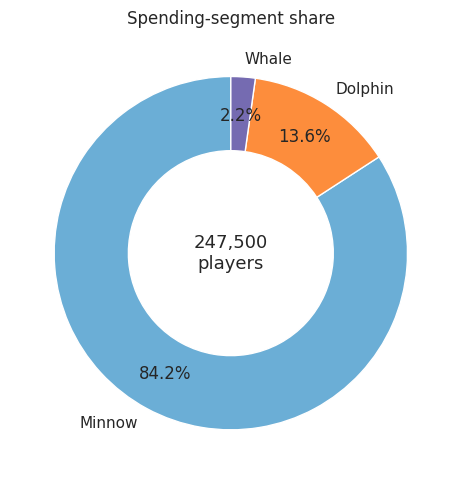

,players,share_percent
SpendingSegment,,
Minnow,208328,84.17
Dolphin,33670,13.60
Whale,5502,2.22


In [28]:
counts = df['SpendingSegment'].value_counts().reindex(segment_order, fill_value=0)
shares = (counts / len(df) * 100).round(2)
fig, ax = plt.subplots(figsize=(7,5))
ax.pie(counts, labels=segment_order, autopct='%1.1f%%', startangle=90,
       colors=[segment_colors[s] for s in segment_order], pctdistance=.78,
       wedgeprops={'width':.42, 'edgecolor':'white'})
ax.text(0,0,f'{len(df):,}\nplayers',ha='center',va='center',fontsize=13)
ax.set_title('Spending-segment share')
plt.tight_layout(); plt.show()
display(pd.DataFrame({'players':counts, 'share_percent':shares}))


## 5. Which game genres show stronger purchase behavior?

In [29]:
# Purchase conversion is based on PurchaseCount30d > 0, not a positive/imputed IAP amount.
df['HasPurchase30d'] = df['PurchaseCount30d'].fillna(0) > 0
if 'InAppPurchaseAmountWasMissing' in df.columns:
    df['AmountKnown'] = df['InAppPurchaseAmountWasMissing'] == 0
else:
    df['AmountKnown'] = df['InAppPurchaseAmount'].notna()
df['IAPForSummary'] = df['InAppPurchaseAmount'].where(df['AmountKnown'])
if 'InAppPurchaseAmountWasMissing' not in df.columns:
    print('Amount summaries use values stored in the fixed CSV; some may be imputed, so do not interpret them as verified observed revenue.')

In [30]:
def summarize_group(column):
    summary = df.groupby(column, dropna=False).agg(
        players=(column, 'size'),
        purchasers=('HasPurchase30d', 'sum'),
        total_iap_used_for_summary=('IAPForSummary', 'sum'),
        mean_iap_used_for_summary=('IAPForSummary', 'mean'),
        median_iap_used_for_summary=('IAPForSummary', 'median'),
        mean_purchase_count=('PurchaseCount30d', 'mean')
    )
    summary['purchase_rate_percent'] = 100 * summary['purchasers'] / summary['players'].replace(0,np.nan)
    return summary.sort_values('mean_iap_used_for_summary', ascending=False)
genre_summary = summarize_group('GameGenre')
display(genre_summary.round(2))
minimum_players = 100
genre_plot = genre_summary[genre_summary['players'] >= minimum_players].copy()
genre_plot['Genre'] = genre_plot.index.astype(str)
genre_plot = genre_plot.sort_values('purchase_rate_percent').tail(15)
fig = px.bar(genre_plot, x='purchase_rate_percent', y='Genre', orientation='h',
             color='purchase_rate_percent', color_continuous_scale='Blues',
             text='purchase_rate_percent',
             hover_data={'players':':,','mean_iap_used_for_summary':':.2f',
                         'mean_purchase_count':':.2f','purchase_rate_percent':':.2f'},
             title='30-day purchase conversion by game genre (groups with n ≥ 100)')
fig.update_traces(texttemplate='%{x:.1f}%', textposition='outside', cliponaxis=False)
fig.update_layout(xaxis_title='Players with at least one 30-day purchase (%)', yaxis_title='Game genre',
                  coloraxis_showscale=False, height=560, margin=dict(l=120,r=50,t=60,b=50))
fig.show()

,players,purchasers,total_iap_used_for_summary,mean_iap_used_for_summary,median_iap_used_for_summary,mean_purchase_count,purchase_rate_percent
GameGenre,,,,,,,
Battle Royale,15431,5662,2239400.77,157.14,12.07,0.53,36.69
Racing,15540,5915,2254461.32,156.38,12.58,0.54,38.06
Strategy,16174,5993,2161014.52,143.26,11.02,0.54,37.05
Fighting,14781,5645,1903264.29,138.54,12.38,0.55,38.19
MOBA,14893,5446,1926150.63,138.42,11.81,0.51,36.57
Unknown,4923,1796,519032.45,114.4,13.58,0.51,36.48
Adventure,13846,5397,1237102.17,96.2,11.91,0.55,38.98
MMORPG,16024,5724,1371521.92,92.35,12.47,0.49,35.72
Role Playing,15927,5756,1348122.59,91.37,11.08,0.5,36.14


**What it means:** Longer bars indicate genres with a higher share of players making at least one purchase in 30 days. This can help prioritize genres for campaign tests, but it does not prove that genre causes spending or that a promotion will increase revenue. Check the player counts and test offers before scaling.

## 6. Are ad views associated with purchase behavior?

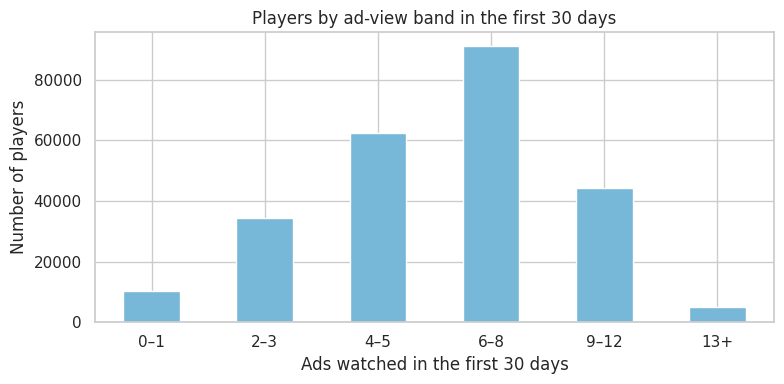

In [52]:
import pandas as pd
import matplotlib.pyplot as plt

# Group ad views into bands
ad_bins = [-1, 1, 3, 5, 8, 12, float("inf")]
ad_labels = ["0–1", "2–3", "4–5", "6–8", "9–12", "13+"]

df["AdViewBand"] = pd.cut(
    df["AdsWatched30d"],
    bins=ad_bins,
    labels=ad_labels
)

# Count players in each band, keeping the intended order
ad_band_counts = (
    df["AdViewBand"]
    .value_counts(sort=False)
    .reindex(ad_labels, fill_value=0)
)

# Plot
fig, ax = plt.subplots(figsize=(8, 4))
ad_band_counts.plot.bar(ax=ax, color="#77B7D8")

ax.set_title("Players by ad-view band in the first 30 days")
ax.set_xlabel("Ads watched in the first 30 days")
ax.set_ylabel("Number of players")
ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

,players,purchase_rate_percent,mean_purchase_count,median_active_days
AdViewBand,,,,
0-1,10243,62.76,1.25,5.0
2-3,34420,42.68,0.66,5.0
4-5,62497,35.10,0.48,5.0
6-8,91062,32.88,0.42,5.0
9-12,44239,33.50,0.42,6.0
13+,5039,36.26,0.46,7.0


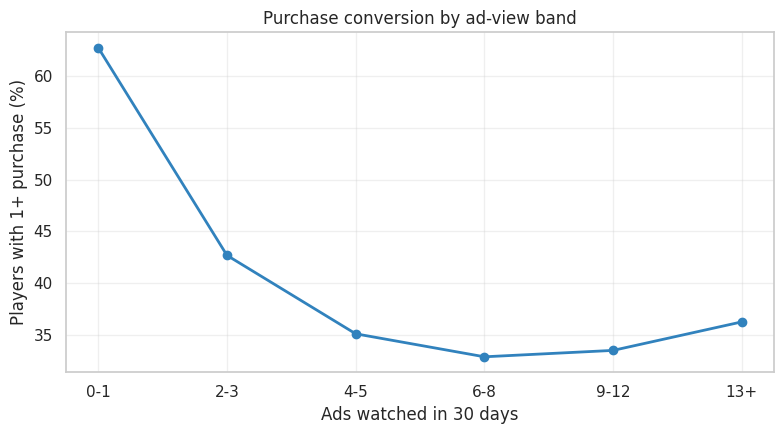

Spearman correlation, AdsWatched30d vs PurchaseCount30d: -0.105


In [58]:
# Keep the rest of your original code
# Ordered ad-view bands; keep one focused purchase-conversion chart.
ad_bins = [-1, 1, 3, 5, 8, 12, np.inf]
ad_labels = ["0-1", "2-3", "4-5", "6-8", "9-12", "13+"]

df["AdViewBand"] = pd.cut(
    df["AdsWatched30d"],
    bins=ad_bins,
    labels=ad_labels
)

ad_summary = df.groupby("AdViewBand", observed=False).agg(
    players=("AdViewBand", "size"),
    purchase_rate=("HasPurchase30d", "mean"),
    mean_purchase_count=("PurchaseCount30d", "mean"),
    median_active_days=("ActiveDays30d", "median")
)

ad_summary["purchase_rate_percent"] = 100 * ad_summary["purchase_rate"]

display(
    ad_summary[
        ["players", "purchase_rate_percent", "mean_purchase_count", "median_active_days"]
    ].round(2)
)

fig, ax = plt.subplots(figsize=(8, 4.5))
ad_summary["purchase_rate_percent"].plot(
    marker="o",
    linewidth=2,
    color="#3182bd",
    ax=ax
)
ax.set_title("Purchase conversion by ad-view band")
ax.set_xlabel("Ads watched in 30 days")
ax.set_ylabel("Players with 1+ purchase (%)")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(
    "Spearman correlation, AdsWatched30d vs PurchaseCount30d:",
    round(
        df[["AdsWatched30d", "PurchaseCount30d"]]
        .corr(method="spearman")
        .iloc[0, 1],
        3
    )
)

## 7. Does activity relate to spending or purchase frequency?

Compare active days and session count with spending tier and purchase count. Use scatter/hexbin-style density and boxplots because large datasets create overplotting. Purchase count is appropriate for descriptive analysis; whether it is valid as a model input depends on the prediction time.

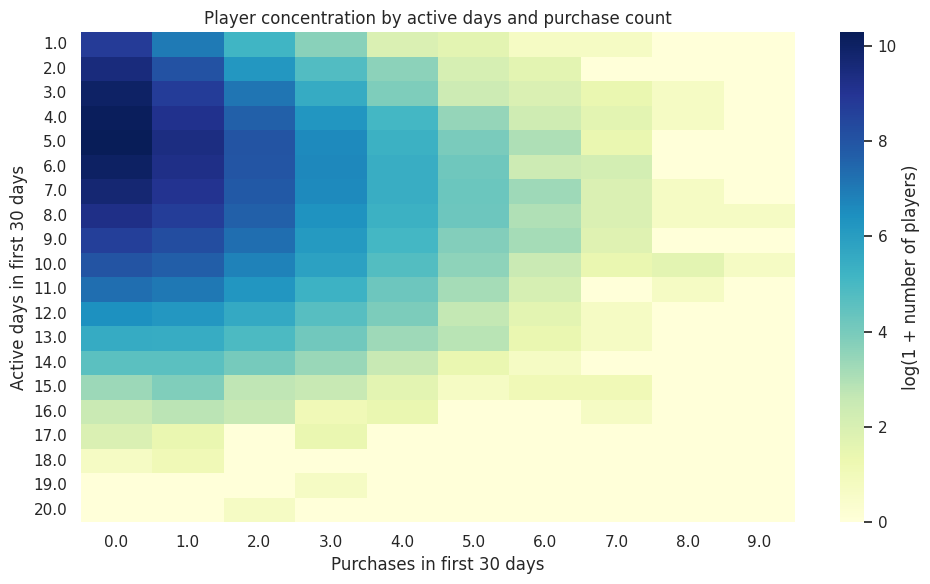

In [32]:
activity_counts = pd.crosstab(df['ActiveDays30d'], df['PurchaseCount30d']).sort_index()
plt.figure(figsize=(10,6))
sns.heatmap(np.log1p(activity_counts), cmap='YlGnBu', cbar_kws={'label':'log(1 + number of players)'})
plt.title('Player concentration by active days and purchase count')
plt.xlabel('Purchases in first 30 days'); plt.ylabel('Active days in first 30 days')
plt.tight_layout(); plt.show()

**What it means:** Darker cells show combinations of activity days and purchase counts with more players. This describes the dataset’s concentration; it does not show purchase rates or prove that being active more days causes purchases.

### Active days by spending segment
This boxplot compares the distribution of days active, without mixing it with the purchase-count heatmap.

/tmp/ipykernel_395/1254972695.py:2: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




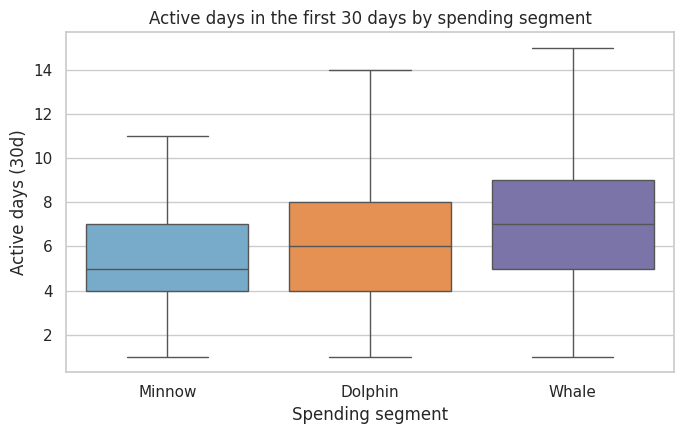

In [33]:
plt.figure(figsize=(7,4.5))
sns.boxplot(data=df, x='SpendingSegment', y='ActiveDays30d', order=segment_order,
            palette=segment_colors, showfliers=False)
plt.title('Active days in the first 30 days by spending segment')
plt.xlabel('Spending segment'); plt.ylabel('Active days (30d)')
plt.tight_layout(); plt.show()

**What it means:** The boxes compare typical active days across spending tiers. If the median is higher for a higher-spending tier, those players were more active in this dataset. This is an association, not proof that increasing activity will increase spending.

In [34]:
print('Spearman correlations (descriptive only):')
display(df[['ActiveDays30d','SessionCount','AdsWatched30d','PurchaseCount30d','InAppPurchaseAmount']].corr(method='spearman').round(3))

Spearman correlations (descriptive only):


,ActiveDays30d,SessionCount,AdsWatched30d,PurchaseCount30d,InAppPurchaseAmount
ActiveDays30d,1.000,0.143,0.209,0.201,0.080
SessionCount,0.143,1.000,0.032,0.032,0.001
AdsWatched30d,0.209,0.032,1.000,-0.105,-0.236
PurchaseCount30d,0.201,0.032,-0.105,1.000,0.210
InAppPurchaseAmount,0.080,0.001,-0.236,0.210,1.000


## 8. When does the first purchase happen after installation?

Analyze elapsed days and compare by spending tier. The cleaning notebook preserves `FirstPurchaseDaysAfterInstallWasMissing` as a numeric 0/1 indicator. This chart uses values where the indicator is 0, so median-filled values do not distort observed-delay summaries.

Rows used for observed first-purchase-delay analysis: 208006


/tmp/ipykernel_395/2211792524.py:13: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




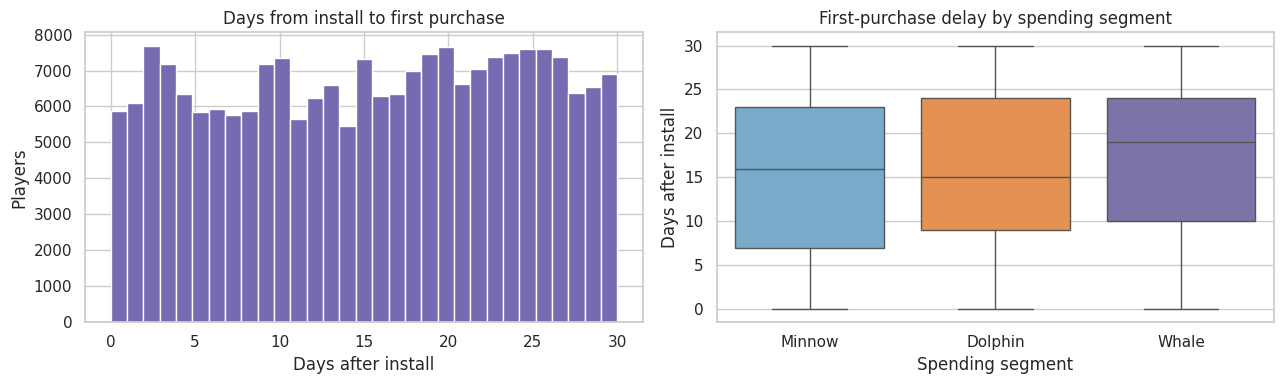

,count,median,mean,min,max
SpendingSegment,,,,,
Minnow,175273,16.0,15.28,0.0,30.0
Dolphin,28208,15.0,15.87,0.0,30.0
Whale,4525,19.0,16.58,0.0,30.0


In [35]:
if 'FirstPurchaseDaysAfterInstallWasMissing' in df.columns:
    delay_data = df.loc[df['FirstPurchaseDaysAfterInstallWasMissing'].eq(0)].copy()
else:
    delay_data = df.dropna(subset=['FirstPurchaseDaysAfterInstall']).copy()
    print('No 0/1 delay indicator is present; values are analyzed as stored in the cleaned CSV.')
delay = delay_data['FirstPurchaseDaysAfterInstall'].dropna()
print('Rows used for observed first-purchase-delay analysis:', len(delay))
fig, axes = plt.subplots(1,2,figsize=(13,4))
axes[0].hist(delay, bins=31, color='#756bb1', edgecolor='white')
axes[0].set_title('Days from install to first purchase')
axes[0].set_xlabel('Days after install'); axes[0].set_ylabel('Players')
delay_by_segment = delay_data
sns.boxplot(data=delay_by_segment, x='SpendingSegment', y='FirstPurchaseDaysAfterInstall',
            order=segment_order, palette=segment_colors, showfliers=False, ax=axes[1])
axes[1].set_title('First-purchase delay by spending segment')
axes[1].set_xlabel('Spending segment'); axes[1].set_ylabel('Days after install')
plt.tight_layout(); plt.show()
display(delay_by_segment.groupby('SpendingSegment')['FirstPurchaseDaysAfterInstall'].agg(
    ['count','median','mean','min','max']).reindex(segment_order).round(2))


**What it means — delay histogram:** This shows how many observed players made their first purchase at different times after install. It can help choose when to test an onboarding message.

**What it means — segment boxplot:** This compares the typical first-purchase delay across spending tiers. Differences can suggest timing hypotheses, but do not prove a message or discount will change behavior. The analysis excludes rows flagged as having missing delay values.

## 9. Which countries show more purchasing? Which devices are used?

Rank countries and devices by 30-day purchase conversion (`PurchaseCount30d > 0`) and mean IAP among values retained as observed by the 0/1 indicator. Also compare sample size. Total spend alone can be dominated by large groups. The minimum group-size threshold below is for stability/readability, not a significance test.

In [36]:
country_summary = summarize_group('Country')
device_summary = summarize_group('Device')
print('Country results:')
display(country_summary.round(2))
print('Device results:')
display(device_summary.round(2))

Country results:


,players,purchasers,total_iap_used_for_summary,mean_iap_used_for_summary,median_iap_used_for_summary,mean_purchase_count,purchase_rate_percent
Country,,,,,,,
Afghanistan,7241,2804,1532498.24,221.52,12.21,0.58,38.72
Bangladesh,8029,3107,1302742.39,169.96,14.58,0.58,38.7
India,19184,7088,2623343.65,144.66,13.42,0.52,36.95
South Korea,8258,3125,1133343.05,143.48,11.72,0.55,37.84
Russia,7362,2804,959239.83,140.34,11.86,0.54,38.09
Sri Lanka,6969,2611,920811.64,139.9,14.25,0.55,37.47
Italy,8869,3172,1103444.5,134.8,12.37,0.51,35.77
Denmark,8213,2940,1022722.04,134.59,13.31,0.5,35.8
Canada,8349,2986,1000402.21,133.94,12.21,0.5,35.76


Device results:


,players,purchasers,total_iap_used_for_summary,mean_iap_used_for_summary,median_iap_used_for_summary,mean_purchase_count,purchase_rate_percent
Device,,,,,,,
Unknown,4946,1919,769222.51,169.88,12.56,0.58,38.8
iOS,100524,36606,10173181.69,109.12,12.89,0.51,36.42
Android,142030,51123,12587490.77,94.76,11.52,0.5,35.99


In [37]:
min_group = 100
country_plot = country_summary[(country_summary['players'] >= min_group) & (country_summary.index.astype(str) != 'Unknown')].copy()
country_plot['CountryName'] = country_plot.index.astype(str)
country_plot = country_plot.sort_values('purchase_rate_percent').tail(15)
fig = px.bar(country_plot, x='purchase_rate_percent', y='CountryName', orientation='h',
             color='purchase_rate_percent', color_continuous_scale='Oranges', text='purchase_rate_percent',
             hover_data={'players':':,','mean_iap_used_for_summary':':.2f','mean_purchase_count':':.2f'},
             title='Purchase conversion by country (groups with n ≥ 100; top 15)')
fig.update_traces(texttemplate='%{x:.1f}%', textposition='outside', cliponaxis=False)
fig.update_layout(xaxis_title='Players with at least one 30-day purchase (%)', yaxis_title='Country',
                  coloraxis_showscale=False, height=560, margin=dict(l=120,r=50,t=60,b=50))
fig.show()

**What it means:** Longer bars show countries with a higher 30-day purchase rate among the displayed groups. Use the sample sizes when comparing countries; a high rate alone does not prove a campaign will perform better there. Treat this as a test idea, not a targeting rule.

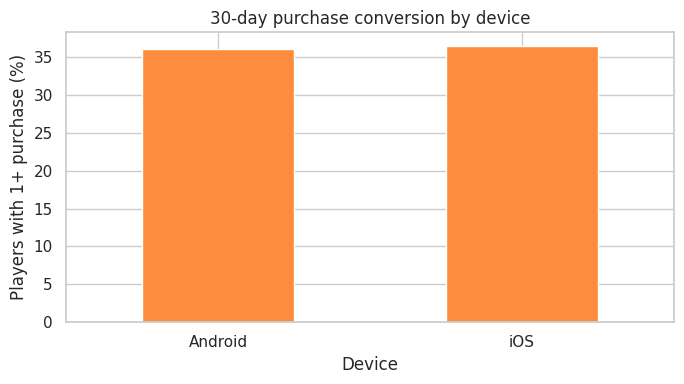

In [38]:
device_plot = (
    df.assign(has_purchase=df["PurchaseCount30d"] > 0)
      .groupby("Device")
      .agg(
          players=("Device", "size"),
          purchase_rate_percent=("has_purchase", lambda x: x.mean() * 100)
      )
)

# Hide Unknown and very small groups, if any
device_plot = device_plot[
    (device_plot.index != "Unknown") &
    (device_plot["players"] >= 100)
].sort_values("purchase_rate_percent")

fig, ax = plt.subplots(figsize=(7, 4))
device_plot["purchase_rate_percent"].plot.bar(ax=ax, color="#fd8d3c")

ax.set_title("30-day purchase conversion by device")
ax.set_xlabel("Device")
ax.set_ylabel("Players with 1+ purchase (%)")
ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

**What it means:** This compares the share of players with a purchase on each device type. A difference may help plan device-specific campaign tests, but it does not show that device type causes purchases.

## 10. Do acquisition channel, payment method, or social features differ?

These are practical campaign questions: which acquisition sources bring players with stronger recorded purchase signals, which payment methods appear among spenders, and whether guild membership or push opt-in is associated with activity/spending. Use within-group rates and median spend, not raw totals alone.

,players,purchasers,total_iap_used_for_summary,mean_iap_used_for_summary,median_iap_used_for_summary,mean_purchase_count,purchase_rate_percent
AcquisitionChannel,,,,,,,
Referral,30510,11078,3062491.46,107.65,11.88,0.51,36.31
Organic,58735,21320,5773585.51,105.54,11.88,0.51,36.3
Unknown,12375,4401,1186377.41,102.96,11.88,0.5,35.56
Influencer,28292,10250,2675570.14,101.65,11.98,0.5,36.23
Cross-promotion,28080,10108,2637219.79,100.5,12.16,0.51,36.0
Paid Social,56410,20593,5226707.94,99.5,11.88,0.51,36.51
Search Ads,33098,11898,2967942.72,96.3,11.86,0.5,35.95


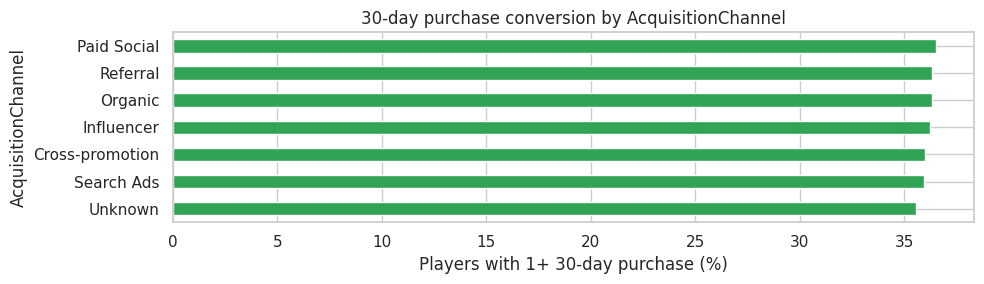

In [39]:
for column in ['AcquisitionChannel']:
    summary = summarize_group(column)
    display(summary.round(2))
    eligible = summary[summary['players'] >= min_group].sort_values('purchase_rate_percent')
    fig, ax = plt.subplots(figsize=(10, max(3, .35 * len(eligible))))
    eligible['purchase_rate_percent'].plot.barh(ax=ax, color='#31a354')
    ax.set_title(f'30-day purchase conversion by {column}')
    ax.set_xlabel('Players with 1+ 30-day purchase (%)')
    ax.set_ylabel(column)
    plt.tight_layout(); plt.show()


**What it means:** The bars compare 30-day purchase rates across acquisition channels. Channels with higher rates may bring in players with stronger recorded purchase activity, but compare group sizes and acquisition costs before moving budget. The chart does not measure incremental campaign impact.

,players,purchasers,total_iap_used_for_summary,mean_iap_used_for_summary,median_iap_used_for_summary,mean_purchase_count,purchase_rate_percent
PaymentMethod,,,,,,,
Debit Card,34092,12477,4224870.61,127.0,12.58,0.52,36.6
PayPal,31377,11489,3708613.97,121.2,11.97,0.52,36.62
Unknown,21783,8065,1143984.97,109.15,11.86,0.52,37.02
Gift Card,33141,12437,3370252.28,104.2,12.55,0.53,37.53
Carrier Billing,32558,11821,3138599.69,98.93,11.85,0.51,36.31
Credit Card,31839,11282,2912806.36,93.79,10.98,0.48,35.43
Google Pay,33562,11869,2761250.19,84.39,12.16,0.49,35.36
Apple Pay,29148,10208,2269516.9,79.94,11.63,0.47,35.02


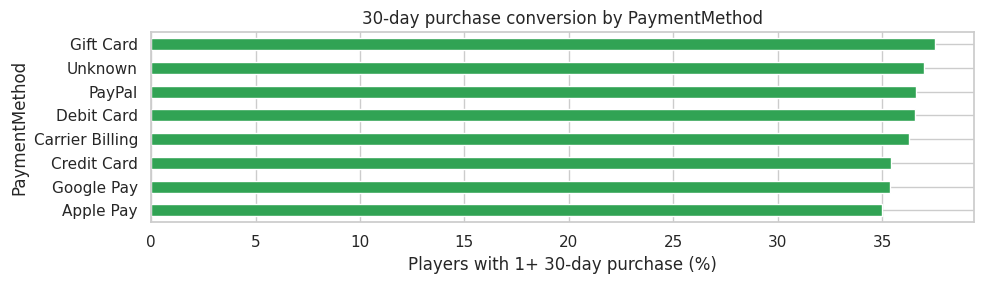

In [40]:
for column in ['PaymentMethod']:
    summary = summarize_group(column)
    display(summary.round(2))
    eligible = summary[summary['players'] >= min_group].sort_values('purchase_rate_percent')
    fig, ax = plt.subplots(figsize=(10, max(3, .35 * len(eligible))))
    eligible['purchase_rate_percent'].plot.barh(ax=ax, color='#31a354')
    ax.set_title(f'30-day purchase conversion by {column}')
    ax.set_xlabel('Players with 1+ 30-day purchase (%)')
    ax.set_ylabel(column)
    plt.tight_layout(); plt.show()


**What it means:** The bars compare purchase rates across recorded payment methods. The groups may differ in who uses them, so this is not evidence that changing payment methods will increase purchases. Use it to identify questions for checkout testing.

,players,purchasers,total_iap_used_for_summary,mean_iap_used_for_summary,median_iap_used_for_summary,mean_purchase_count,purchase_rate_percent
GuildMember,,,,,,,
Yes,60801,24141,8368555.84,147.94,12.62,0.58,39.7
No,186699,65507,15161339.13,87.13,11.74,0.48,35.09


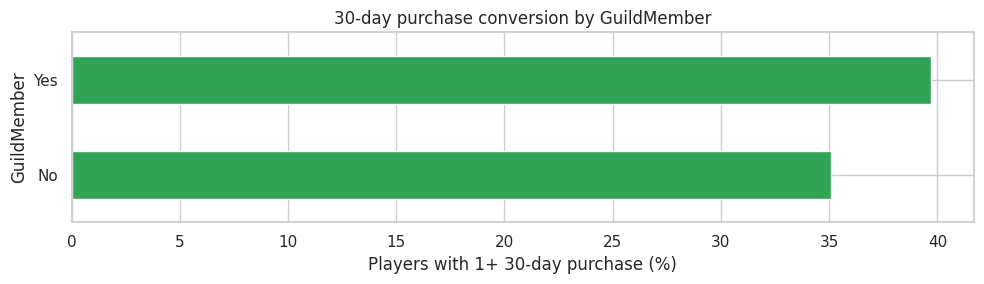

In [41]:
for column in ['GuildMember']:
    summary = summarize_group(column)
    display(summary.round(2))
    eligible = summary[summary['players'] >= min_group].sort_values('purchase_rate_percent')
    fig, ax = plt.subplots(figsize=(10, max(3, .35 * len(eligible))))
    eligible['purchase_rate_percent'].plot.barh(ax=ax, color='#31a354')
    ax.set_title(f'30-day purchase conversion by {column}')
    ax.set_xlabel('Players with 1+ 30-day purchase (%)')
    ax.set_ylabel(column)
    plt.tight_layout(); plt.show()


**What it means:** This compares purchase rates for guild members and non-members. A higher rate for guild members would be an association, not proof that joining a guild causes purchases. Consider a controlled guild-engagement test before acting on it.

,players,purchasers,total_iap_used_for_summary,mean_iap_used_for_summary,median_iap_used_for_summary,mean_purchase_count,purchase_rate_percent
PushNotificationsOptIn,,,,,,,
Yes,100651,38411,11558008.12,123.3,12.37,0.55,38.16
No,146849,51237,11971886.85,87.48,11.73,0.48,34.89


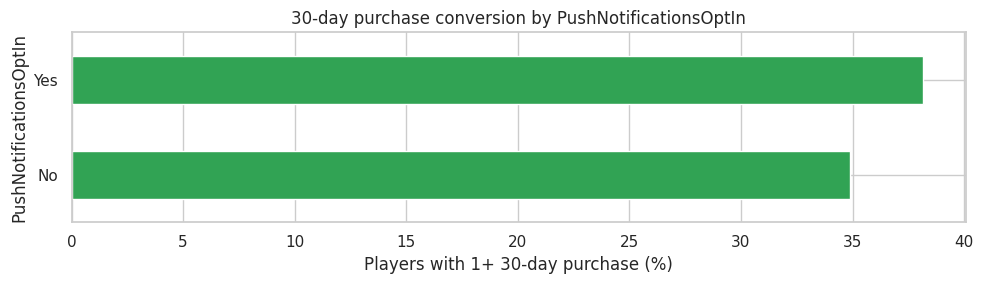

In [42]:
for column in ['PushNotificationsOptIn']:
    summary = summarize_group(column)
    display(summary.round(2))
    eligible = summary[summary['players'] >= min_group].sort_values('purchase_rate_percent')
    fig, ax = plt.subplots(figsize=(10, max(3, .35 * len(eligible))))
    eligible['purchase_rate_percent'].plot.barh(ax=ax, color='#31a354')
    ax.set_title(f'30-day purchase conversion by {column}')
    ax.set_xlabel('Players with 1+ 30-day purchase (%)')
    ax.set_ylabel(column)
    plt.tight_layout(); plt.show()


**What it means:** This compares purchase rates for players who opted in or out of push notifications. A difference can guide a messaging test, but opt-in players may already be more engaged. Respect consent and measure incremental results with a test group.

## 11. Do age and gender relate to spending profiles? (descriptive only)

Compare age distributions by spending tier and segment composition by gender. Gender is included only to describe this dataset; do not use sensitive characteristics to exclude players or make unsupported targeting decisions.

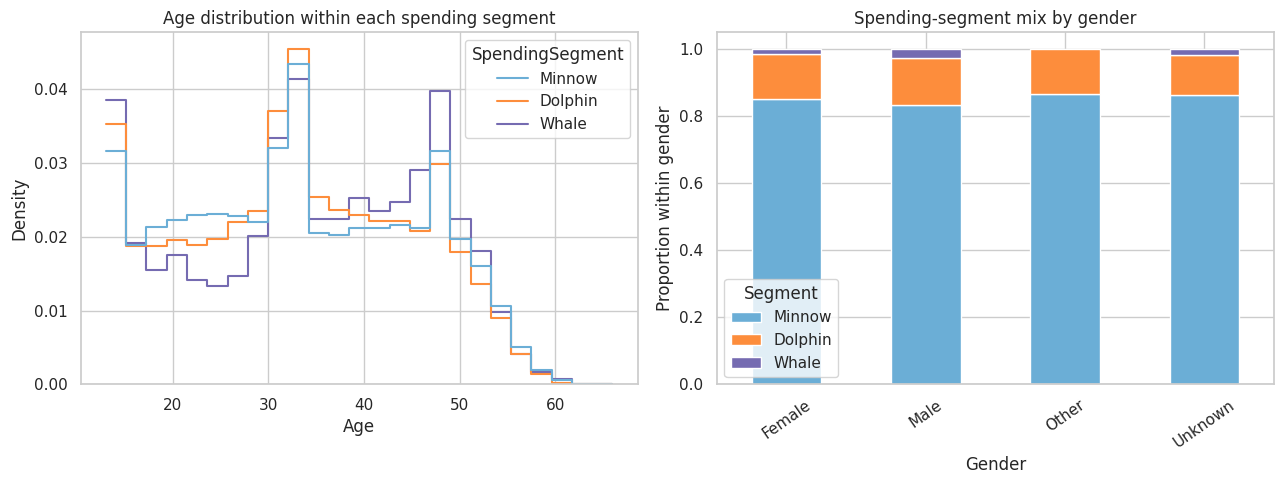

In [43]:
fig, axes = plt.subplots(1,2,figsize=(13,5))
sns.histplot(data=df, x='Age', hue='SpendingSegment', hue_order=segment_order,
             palette=segment_colors, bins=25, stat='density', common_norm=False,
             element='step', fill=False, ax=axes[0])
axes[0].set_title('Age distribution within each spending segment')
axes[0].set_xlabel('Age'); axes[0].set_ylabel('Density')

gender_mix = pd.crosstab(df['Gender'], df['SpendingSegment'], normalize='index').reindex(columns=segment_order, fill_value=0)
gender_mix.plot.bar(stacked=True, ax=axes[1], color=[segment_colors[s] for s in segment_order])
axes[1].set_title('Spending-segment mix by gender')
axes[1].set_xlabel('Gender'); axes[1].set_ylabel('Proportion within gender'); axes[1].tick_params(axis='x',rotation=35)
axes[1].legend(title='Segment')
plt.tight_layout(); plt.show()


**What it means — age chart:** This compares age distributions across spending tiers. Differences describe this dataset only and should not be used alone to target or exclude players.

**What it means — gender chart:** This shows the spending-tier mix within each recorded gender group. Treat it as descriptive only; do not use gender to exclude players or make unsupported targeting decisions.

## 12. Date-based patterns

Inspect monthly counts for valid install and last-purchase dates. Because the dataset includes missing and simulated dates, state the number of valid dates and interpret trends cautiously. Calendar patterns in this dataset are not proof of seasonal demand.

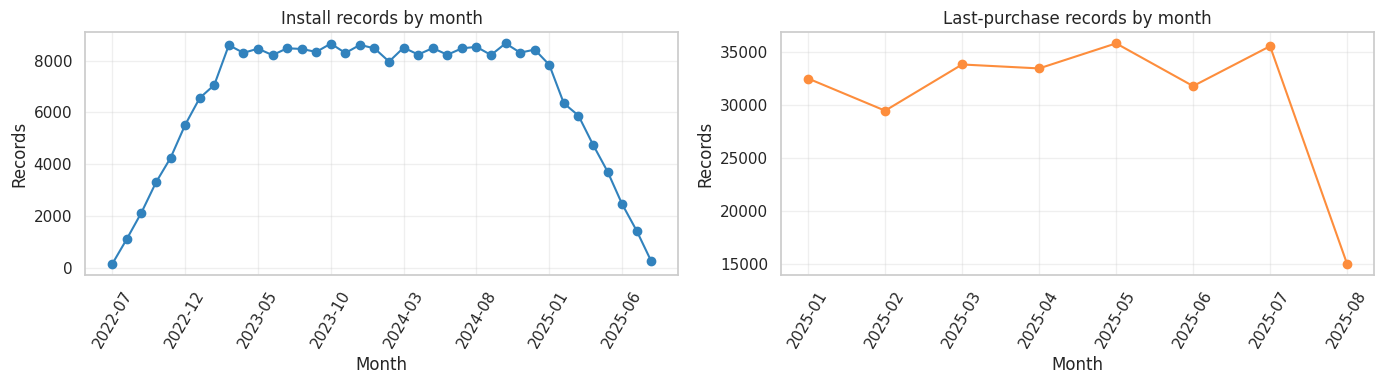

Valid install dates: 247500
Valid last-purchase dates: 247500


In [44]:
fig, axes = plt.subplots(1,2,figsize=(14,4))
for ax, column, label, color in [
    (axes[0], 'InstallDate', 'Install records by month', '#3182bd'),
    (axes[1], 'LastPurchaseDate', 'Last-purchase records by month', '#fd8d3c')
]:
    monthly = df[column].dropna().dt.to_period('M').value_counts().sort_index()
    if len(monthly):
        monthly.index = monthly.index.astype(str)
        monthly.plot(ax=ax, marker='o', color=color)
    ax.set_title(label)
    ax.set_xlabel('Month'); ax.set_ylabel('Records')
    ax.tick_params(axis='x',rotation=60)
    ax.grid(True, alpha=.3)
plt.tight_layout(); plt.show()

print('Valid install dates:', int(df['InstallDate'].notna().sum()))
print('Valid last-purchase dates:', int(df['LastPurchaseDate'].notna().sum()))


**What it means:** These lines show the number of records by month, not verified changes in player demand. Dates may be missing or simulated; if missing dates were randomly filled, the filled dates do not represent real event timing. Do not use these trends to schedule campaigns or claim seasonality.

## 13. Feature engineering: create new player-behavior features

This is the feature-engineering stage: it creates new columns from existing behavior data, rather than only plotting the original columns.

- `AdsPerActiveDay`: ad exposure rate per day played.
- `PurchasesPerActiveDay`: purchase frequency adjusted for days active; only valid as a predictor after the 30-day window.
- `SocialActionsPerActiveDay` and `SessionsPerActiveDay`: activity intensity rates.
- `EngagementActions30d`: combined count of ads watched and social actions.
- `EngagementActionsPerActiveDay`: combined engagement intensity per day active.

Rates make players with different active-day counts more comparable. These features are hypotheses; test whether they add value in modeling.


Raw counts partly depend on how many days a player was active. Create interpretable rates per active day. These features help compare players with different activity levels. Keep purchase-derived rates only if the model's prediction time is after the 30-day observation window.

Created: ['EngagementActions30d', 'AdsPerActiveDay', 'PurchasesPerActiveDay', 'SocialActionsPerActiveDay', 'SessionsPerActiveDay', 'EngagementActionsPerActiveDay']


,EngagementActions30d,AdsPerActiveDay,PurchasesPerActiveDay,SocialActionsPerActiveDay,SessionsPerActiveDay,EngagementActionsPerActiveDay
SpendingSegment,,,,,,
Minnow,9.0,1.25,0.0,0.5,2.0,1.8
Dolphin,7.0,0.625,0.167,0.545,1.714,1.2
Whale,5.0,0.143,0.333,0.571,1.6,0.75


/tmp/ipykernel_395/4046943645.py:15: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


/tmp/ipykernel_395/4046943645.py:15: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


/tmp/ipykernel_395/4046943645.py:15: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


/tmp/ipykernel_395/4046943645.py:15: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


/tmp/ipykernel_395/4046943645.py:15: FutureWarning:



Passing `palette` without assigning `hue` is deprecated a

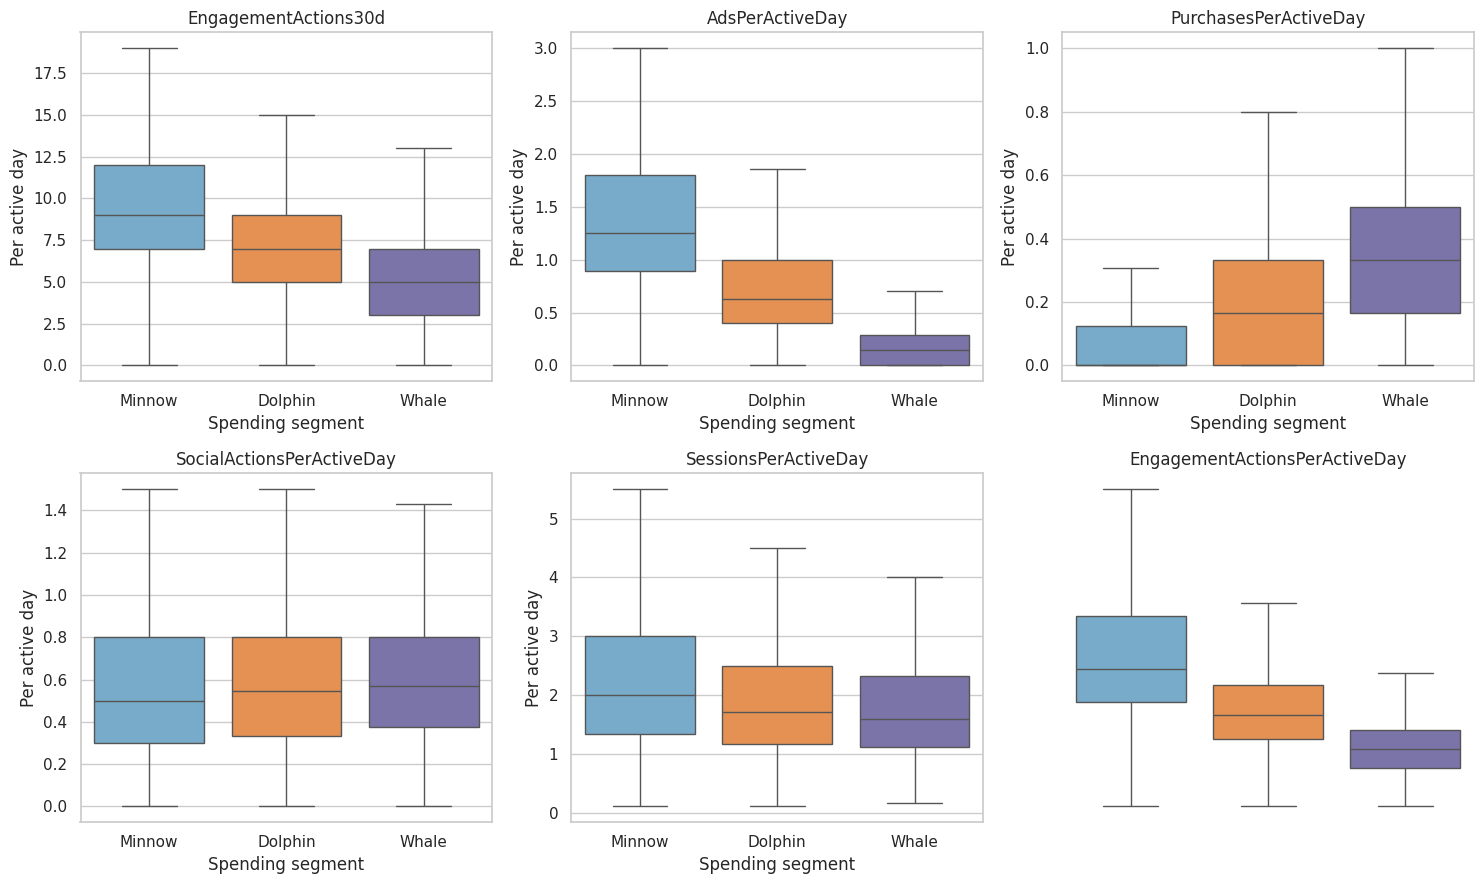

In [45]:
active_days = df['ActiveDays30d'].where(df['ActiveDays30d'] > 0)
df['EngagementActions30d'] = df['AdsWatched30d'] + df['SocialActions30d']
df['AdsPerActiveDay'] = df['AdsWatched30d'] / active_days
df['PurchasesPerActiveDay'] = df['PurchaseCount30d'] / active_days
df['SocialActionsPerActiveDay'] = df['SocialActions30d'] / active_days
df['SessionsPerActiveDay'] = df['SessionCount'] / active_days
df['EngagementActionsPerActiveDay'] = df['EngagementActions30d'] / active_days

new_features = ['EngagementActions30d','AdsPerActiveDay','PurchasesPerActiveDay','SocialActionsPerActiveDay','SessionsPerActiveDay','EngagementActionsPerActiveDay']
print('Created:', new_features)
display(df.groupby('SpendingSegment')[new_features].median().reindex(segment_order).round(3))

fig, axes = plt.subplots(2,3,figsize=(15,9))
for ax, feature in zip(axes.flat, new_features):
    sns.boxplot(data=df, x='SpendingSegment', y=feature, order=segment_order,
                palette=segment_colors, showfliers=False, ax=ax)
    ax.set_title(feature); ax.set_xlabel('Spending segment'); ax.set_ylabel('Per active day')
axes.flat[-1].axis('off')
plt.tight_layout(); plt.show()


**What it means:** These boxplots compare engagement and behavior rates per active day across spending tiers. Higher medians in a tier can point to useful behavior signals, but they do not prove that the behavior causes spending. Purchase-based features are only valid if they are available before the model makes its decision; otherwise they cause data leakage.

### Feature decisions

- **Keep as candidate early-behavior features:** `AdsPerActiveDay`, `SocialActionsPerActiveDay`, `SessionsPerActiveDay`, and `EngagementActionsPerActiveDay`, if observed before the prediction cutoff.
- **Use with timing caution:** `PurchasesPerActiveDay` and `PurchaseCount30d` contain purchase behavior. They may be valid for a decision made after day 30, but are leakage for a prediction made before day 30.
- Compare models with and without engineered features using the same train/test split. Features are useful only if they improve appropriate validation metrics and remain available at decision time.

## 14. Correlation and pairwise relationships

Use a Spearman correlation heatmap for numeric variables because several are skewed or count-valued. This helps spot monotonic relationships and redundant measures. Correlation is not causation and may be affected by the data-generation rules.

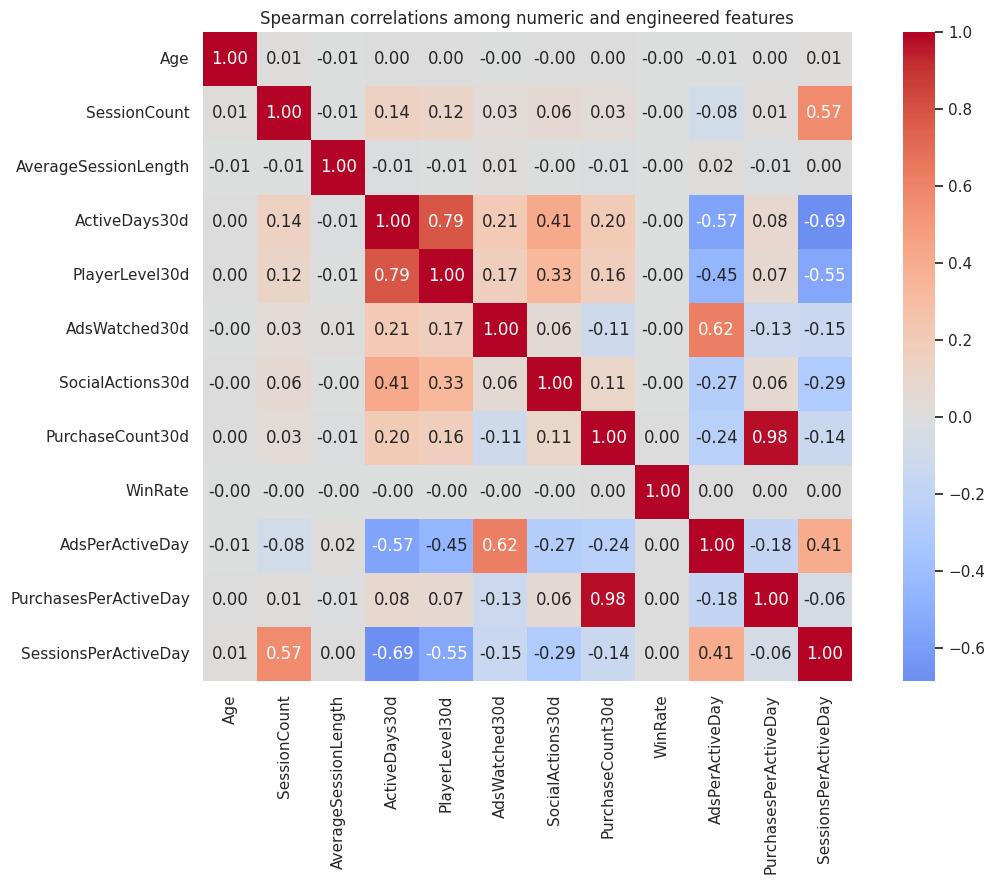

In [46]:
corr_columns = [
    'Age','SessionCount','AverageSessionLength','ActiveDays30d','PlayerLevel30d',
    'AdsWatched30d','SocialActions30d','PurchaseCount30d','WinRate',
    'AdsPerActiveDay','PurchasesPerActiveDay','SessionsPerActiveDay'
]
corr = df[corr_columns].corr(method='spearman')
plt.figure(figsize=(12,9))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True)
plt.title('Spearman correlations among numeric and engineered features')
plt.tight_layout(); plt.show()


**What it means:** The heatmap shows how strongly numeric features move together in this dataset. Strong relationships can help identify useful or redundant model inputs, but correlation does not prove cause and may reflect how the data was generated. Check feature timing before using any variable in a prediction model.

## 15. Automatically print useful findings from this dataset

Use these values to write your EDA findings. Include group size and describe them as patterns in the simulated training set. A top-ranked group is not automatically meaningfully different from the next group.

In [47]:
eligible_genres = genre_summary[(genre_summary['players'] >= min_group) & (genre_summary.index.astype(str) != 'Unknown')]
eligible_countries = country_summary[(country_summary['players'] >= min_group) & (country_summary.index.astype(str) != 'Unknown')]
eligible_devices = device_summary[(device_summary['players'] >= min_group) & (device_summary.index.astype(str) != 'Unknown')]

print('--- Dataset-specific descriptive findings ---')
if len(eligible_genres):
    g = eligible_genres['mean_iap_used_for_summary'].idxmax()
    print(f'Genre highest in mean IAP value used in the summary: {g}; USD {eligible_genres.loc[g, "mean_iap_used_for_summary"]:.2f}; n={int(eligible_genres.loc[g, "players"]):,}')
    g2 = eligible_genres['purchase_rate_percent'].idxmax()
    print(f'Genre highest in 30-day purchase conversion: {g2}; {eligible_genres.loc[g2, "purchase_rate_percent"]:.2f}%; n={int(eligible_genres.loc[g2, "players"]):,}')
if len(eligible_countries):
    c = eligible_countries['mean_iap_used_for_summary'].idxmax()
    print(f'Country highest in mean IAP value used in the summary: {c}; USD {eligible_countries.loc[c, "mean_iap_used_for_summary"]:.2f}; n={int(eligible_countries.loc[c, "players"]):,}')
    c2 = eligible_countries['purchase_rate_percent'].idxmax()
    print(f'Country highest in 30-day purchase conversion: {c2}; {eligible_countries.loc[c2, "purchase_rate_percent"]:.2f}%; n={int(eligible_countries.loc[c2, "players"]):,}')
if len(eligible_devices):
    d = eligible_devices['purchase_rate_percent'].idxmax()
    print(f'Device highest in 30-day purchase conversion: {d}; {eligible_devices.loc[d, "purchase_rate_percent"]:.2f}%; n={int(eligible_devices.loc[d, "players"]):,}')
print('Spearman ads/purchase-count correlation:', round(df[['AdsWatched30d','PurchaseCount30d']].corr(method='spearman').iloc[0,1],3))
print('All outputs are descriptive and based on synthetic training data.')


--- Dataset-specific descriptive findings ---
Genre highest in mean IAP value used in the summary: Battle Royale; USD 157.14; n=15,431
Genre highest in 30-day purchase conversion: Adventure; 38.98%; n=13,846
Country highest in mean IAP value used in the summary: Afghanistan; USD 221.52; n=7,241
Country highest in 30-day purchase conversion: Afghanistan; 38.72%; n=7,241
Device highest in 30-day purchase conversion: iOS; 36.42%; n=100,524
Spearman ads/purchase-count correlation: -0.105
All outputs are descriptive and based on synthetic training data.


## 16. Modeling readiness — avoid target leakage

If the target is `SpendingSegment`, do not use `InAppPurchaseAmount` as a predictor: it defines or directly reveals spending. Do not use information recorded after the prediction time. `PurchaseCount30d` is only valid if the model is applied after the full 30-day period and that matches the business question. Split before fitting encoders, scalers, or imputers.

In [48]:
target = 'SpendingSegment'
# Strict behavior-based candidates; review against your exact prediction cutoff.
candidate_features = [
    'Age','Gender','Country','Device','GameGenre','SessionCount',
    'AverageSessionLength','ActiveDays30d','PlayerLevel30d','AdsWatched30d',
    'SocialActions30d','WinRate','AdsPerActiveDay',
    'SocialActionsPerActiveDay','SessionsPerActiveDay',
    'EngagementActionsPerActiveDay'
]
X = df[candidate_features].copy()
y = df[target].copy()
print('Candidate feature count:', len(candidate_features))
print('X shape:', X.shape, '| y shape:', y.shape)
print('Excluded direct spending measure: InAppPurchaseAmount')


Candidate feature count: 16
X shape: (247500, 16) | y shape: (247500,)
Excluded direct spending measure: InAppPurchaseAmount


## 17. Save the EDA and feature-engineered dataset

In [49]:
OUTPUT_FILE = 'mobile_game_players_eda_features.csv'
df.to_csv(OUTPUT_FILE, index=False)
print('Saved:', OUTPUT_FILE)


Saved: mobile_game_players_eda_features.csv


## conclusion


**Input filename:** `mobile_game_players_cleaned.csv`
**Output filename:** `mobile_game_players_eda_features.csv`
